# 2D Inversion and Inhomogeneous Resistivity
Here we use the fixed-kernel 2D inverter together with our inhomogeneous Ohmic solver to illustrate how inhomogeneous metallic current flows can be reconstructed in sottools.

As always, we begin with importing the required modules and defining a representative test SQUID. The SQUID is is of a realistic size and height close to that used in our [Kagome paper](https://arxiv.org/abs/2606.20157).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sottools.forward as forward
import sottools.mesh as mesh
from sottools import backward
import sottools.utils.meshplotting as meshplotting

params = forward.Forward2DParameters(
    Lx = 6.0,
    Ly = 6.0,
    Nx = 128,
    Ny = 128, # Take care: pixels must be PERFECTLY square
    rho1 = 0.1,
    rho2 = 0.24,
    height = 0.35,
    phi = np.deg2rad(63.0), # Standard TM-SOT sensor tilt angle
    invert_normal=True # Sets the sign of the SQUID response
)
fwd = forward.Forward2DCurrent(params)

Now we define the geometry. We use a single test geometry for all 2D showcases. To smooth out simulation artifacts, we round the corners, which takes a bit of finesse:

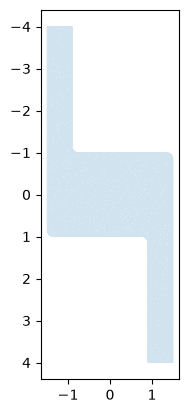

In [2]:
def corner_block_geometry(
    W: float = 3.0,
    H: float = 3.0,
    lead_width: float = 0.6,
    lead_length: float = 2.0,
    corner_radius: float = 0.15,
    n_arc: int = 8,
):
    BM = mesh.SimplyConnectedCurrentMesh.BoundaryMarker
    w, L = lead_width, lead_length
    if not (0 < w < min(W, H)):
        raise ValueError("lead_width must be positive and smaller than the block.")

    # Counter-clockwise polygon: (point, marker of the segment starting here, may round?)
    corners = [
        ((-L, 0.0), BM.DIRICHLET_LEFT, False),      # inlet lead, bottom wall starts
        ((W, 0.0), BM.DIRICHLET_LEFT, True),        # block bottom-right (convex)
        ((W, H - w), BM.DIRICHLET_LEFT, True),      # re-entrant corner into outlet lead
        ((W + L, H - w), BM.NEUMANN_OUT, False),    # outlet (open end)
        ((W + L, H), BM.DIRICHLET_RIGHT, False),
        ((0.0, H), BM.DIRICHLET_RIGHT, True),       # block top-left (convex)
        ((0.0, w), BM.DIRICHLET_RIGHT, True),       # re-entrant corner into inlet lead
        ((-L, w), BM.NEUMANN_IN, False),            # inlet (open end)
    ]

    points, markers = [], []
    n = len(corners)
    for i, (p, marker_out, roundable) in enumerate(corners):
        p = np.asarray(p, dtype=float)
        if not roundable or corner_radius <= 0:
            points.append(p)
            markers.append(marker_out)
            continue

        # Fillet tangent to both edges: unit vectors towards the neighbouring corners
        p_prev = np.asarray(corners[i - 1][0], dtype=float)
        p_next = np.asarray(corners[(i + 1) % n][0], dtype=float)
        a = (p_prev - p) / np.linalg.norm(p_prev - p)
        b = (p_next - p) / np.linalg.norm(p_next - p)
        theta = np.arccos(np.clip(a @ b, -1.0, 1.0))           # angle between the edges
        t = corner_radius / np.tan(theta / 2)                    # corner to tangent point
        if t > 0.5 * min(np.linalg.norm(p_prev - p), np.linalg.norm(p_next - p)):
            raise ValueError(f"corner_radius too large for the corner at {tuple(p)}.")
        centre = p + (a + b) / np.linalg.norm(a + b) * corner_radius / np.sin(theta / 2)
        T1, T2 = p + a * t, p + b * t
        phi1 = np.arctan2(T1[1] - centre[1], T1[0] - centre[0])
        phi2 = np.arctan2(T2[1] - centre[1], T2[0] - centre[0])
        dphi = (phi2 - phi1 + np.pi) % (2 * np.pi) - np.pi      # short way round
        for k in range(n_arc + 1):
            phi = phi1 + dphi * k / n_arc
            points.append(centre + corner_radius * np.array([np.cos(phi), np.sin(phi)]))
            markers.append(marker_out)   # both edges at a rounded corner are the same wall

    # Visual frame (h, u) -> mesh coordinates [x, y] = [-u, h]
    vertices = [[h, u] for h, u in points]
    segments = [[i, (i + 1) % len(vertices)] for i in range(len(vertices))]

    cx, cy = np.mean(vertices, axis=0)
    vertices = [([x-cx, y-cy]) for x, y in vertices]
    return vertices, segments, markers

vertices, segments, segment_markers = corner_block_geometry(W=2.0, H=3.0, lead_length=3.0)
blockmesh = mesh.SimplyConnectedCurrentMesh(
    vertices, segments, segment_markers, max_area=4e-4, refine_distance=0.01
)

fig, ax = plt.subplots(1,1)
meshplotting.plot_mesh(blockmesh, ax, alpha=.2, lw=.2)
plt.show()

Now we build the solver. We use a high resolution mesh (made above) to solve to high accuracy---this can take a while. We make the same of uniform resistivity, with a low-$\rho$ oval in the centre. An analogous thin film system could be a Pt structure with a copper oval deposited on top. Note that sottools works best when keeping units of um, uA, uT.

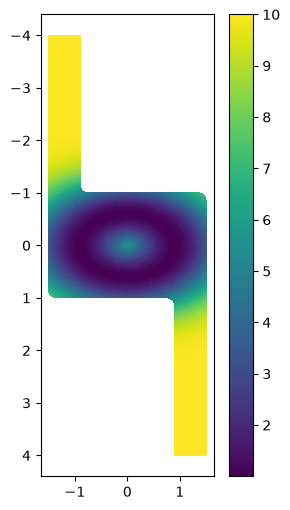

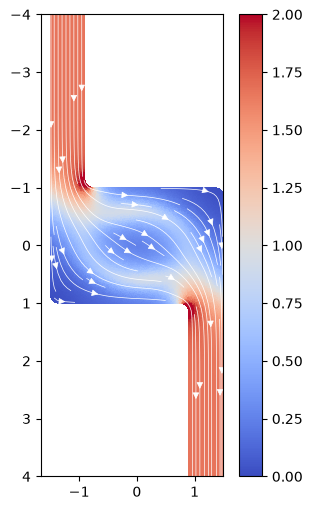

In [3]:
xt, yt = blockmesh.centers.T
R = np.sqrt(xt ** 2 + yt ** 2)
r = .6
sigma = .5
a = 1.5  # stretch factor along y
R_eff = np.sqrt(xt**2 + (yt / a)**2)
rho = 10-9*np.exp(-(R_eff-r)**2/(2*sigma**2))

fig, ax = plt.subplots(1,1,figsize=(4,6))
meshplotting.plot_tc_field(blockmesh, ax, rho)
plt.show()

solver = mesh.InhomogeneousOhmicSolver(blockmesh, rho)
res = solver.solve(left_bc=0.0, right_bc=1.0)

fig, ax = plt.subplots(1,1, figsize=(4,6))
meshplotting.streamplot(blockmesh, ax, res["Kx"], res["Ky"], n_grid=256, density=1.5, cmap='coolwarm', vmin=0.0, vmax=2.0)
plt.show()


We can use the forward object to now calculate the corresponding signal, and try to invert this. However, spuriously, some information about the mesh might end up in this signal. The inversion must be performed on a different, independent mesh. Consequently, we must make a second mesh, slightly perturbed from the original, perfect one. Moreover, we make this second mesh a bit coarser. This stabilizes the inversion.

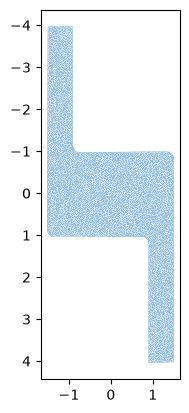

In [4]:
rng = np.random.default_rng(42)
sigma = 0.01
offsetx, offsety = rng.uniform(-0.05, 0.05, size=2)
vertices_perturbed = [([x+rng.normal(0.0, sigma) + offsetx, y+rng.normal(0.0, sigma) + offsety]) for x,y in vertices]
blockmesh_perturbed = mesh.SimplyConnectedCurrentMesh(vertices_perturbed, segments, segment_markers, max_area=1e-3, refine_distance=0.03)

fig, ax = plt.subplots(1,1)
meshplotting.plot_mesh(blockmesh_perturbed, ax, alpha=.5, lw=.2)
plt.show()

Armed with both meshes, we can generate the raw signal and immediately use a backward.Inverter2D object to invert the relation. This takes about 50 seconds on a strong CPU.

In [5]:
m2g_true = forward.MeshToGrid(blockmesh, params)
m2g_perturbed = forward.MeshToGrid(blockmesh_perturbed, params)
signal_raw = fwd.forward(*m2g_true.streamfunction_to_currents(res["streamfunction"]))
inverter = backward.Inverter2D(m2g_perturbed, fwd, signal_raw, lam1=1e-11, lam2=1e-10, lam3=1e-15, lumped_mass=True)

fitres = inverter.fit(lr=1.0, n_steps=200)

C:\Users\LION\sottools\src\sottools\forward.py:1215: UserWarning: Sparse invariant checks are implicitly disabled. Memory errors (e.g. SEGFAULT) will occur when operating on a sparse tensor which violates the invariants, but checks incur performance overhead. To silence this warning, explicitly opt in or out. See `torch.sparse.check_sparse_tensor_invariants.__doc__` for guidance.  (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\aten\src\ATen\Context.cpp:823.)
  torch.sparse_coo_tensor(


To verify the fit worked well, we can plot both the original signal and the fitted signal side-by-side. As we added no noise, and the regularizers are rather light, these should correspond well. The only action of the regularizer can be to smoothen a bit within a single kernel size.

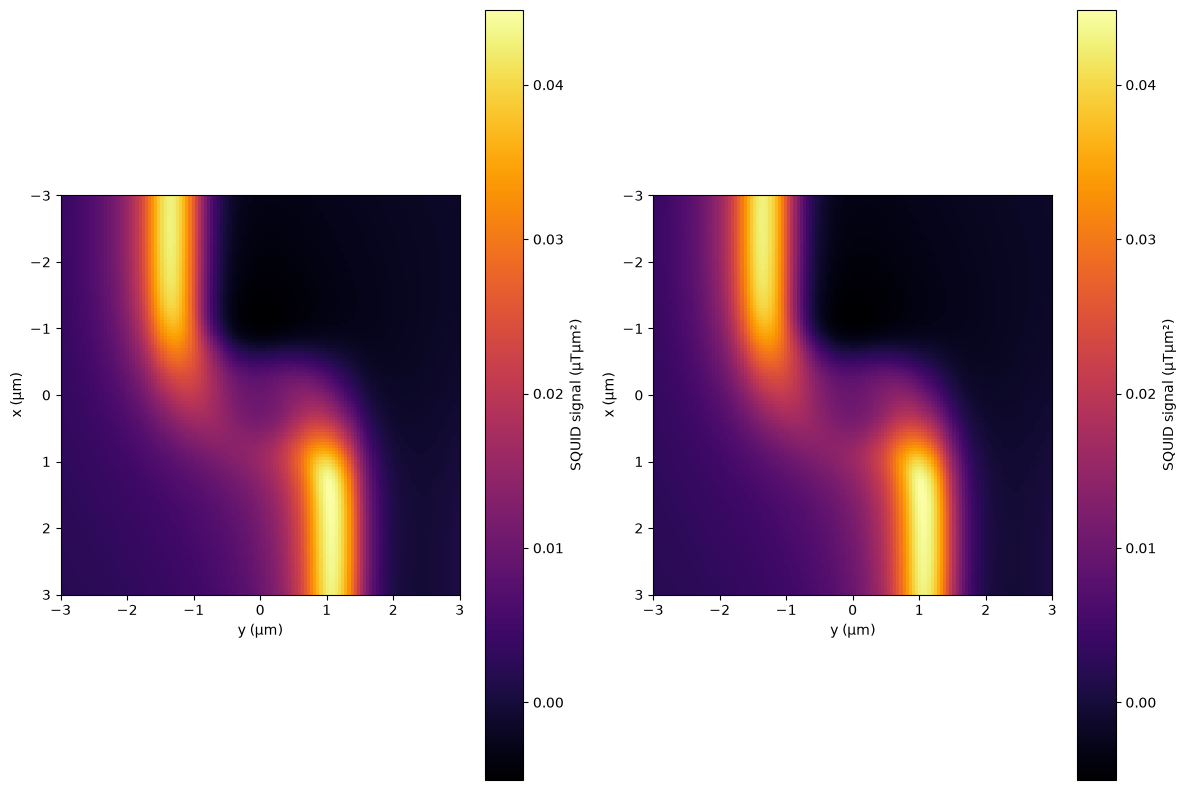

In [6]:
signal_inferred = fwd.forward(*m2g_perturbed.streamfunction_to_currents(fitres["streamfunction"]))

fig, (ax_infer, ax_true) = plt.subplots(1,2,figsize=(12,8))
im0 = ax_infer.imshow(signal_inferred, extent=[-params.Ly / 2, params.Ly / 2, params.Lx / 2, -params.Lx / 2], cmap='inferno')
ax_infer.set_xlabel('y (µm)')
ax_infer.set_ylabel('x (µm)')
ax_infer.set_aspect('equal')
im1 = ax_true.imshow(signal_raw, extent=[-params.Ly / 2, params.Ly / 2, params.Lx / 2, -params.Lx / 2], cmap='inferno')
ax_true.set_xlabel('y (µm)')
ax_true.set_ylabel('x (µm)')
ax_true.set_aspect('equal')
plt.colorbar(im0, ax=ax_infer, label='SQUID signal (µTµm²)')
plt.colorbar(im0, ax=ax_true, label='SQUID signal (µTµm²)')
plt.tight_layout()
plt.show()


Next, we can look directly at the fitted current. Again, perhaps unspected without noise, the fit is of high quality. because the mesh is a bit coarser, this looks slightly granier. In this case, we also see the channels are slightly wider than the original channels. Even without noise, information can get lost due to the final amount of pixels, and the size of the kernel $\approx 300$ nm.

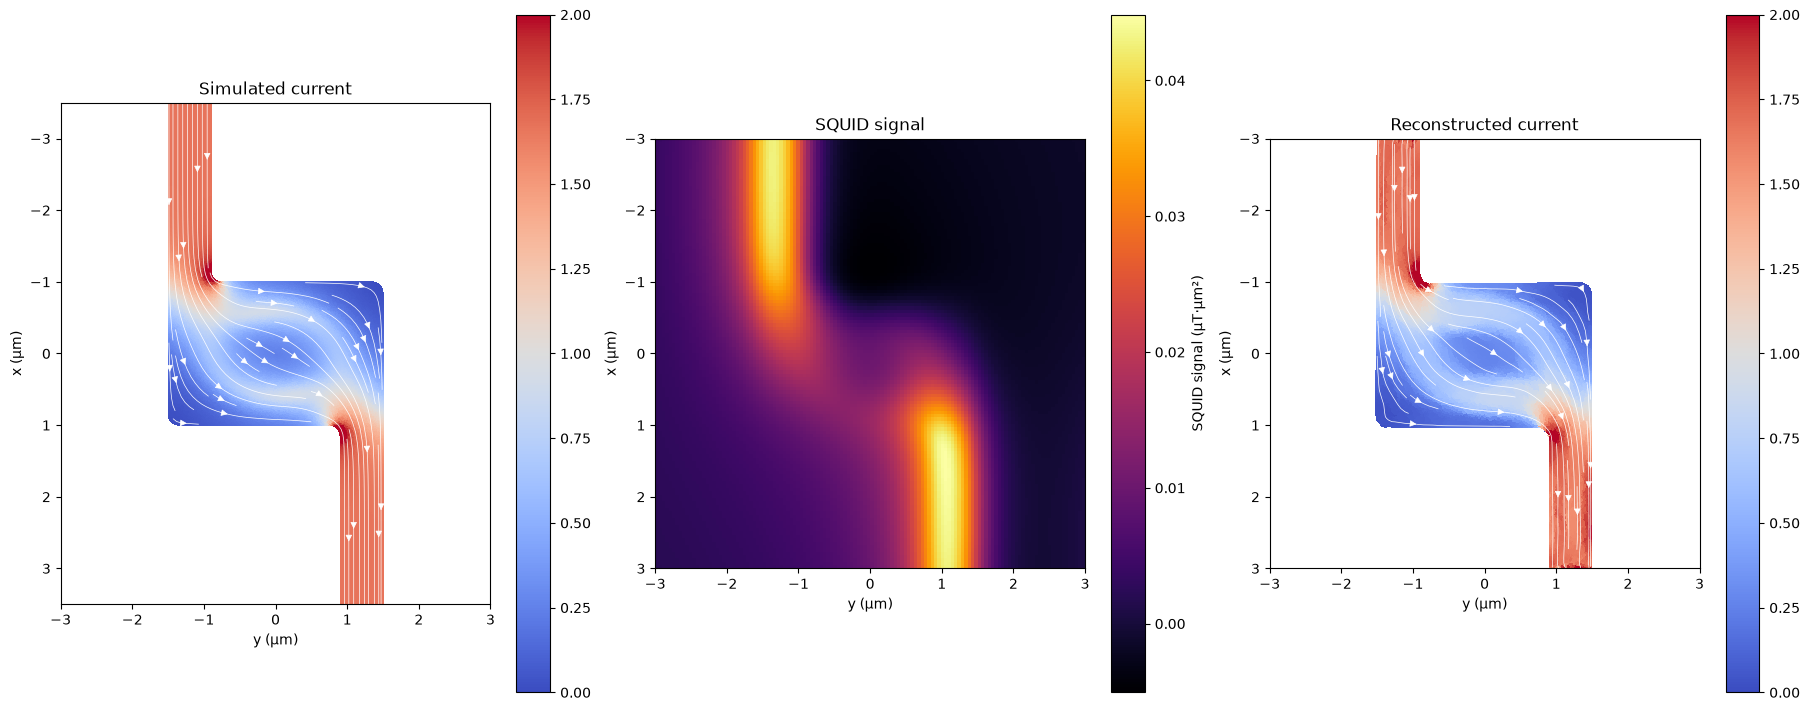

In [7]:
fig, (ax0, ax1, ax2) = plt.subplots(1, 3, figsize=(18, 7), layout="constrained")

# Left: simulated current on the original mesh, 6 um wide by 7 um tall, centred on the device
V = blockmesh.vertices
xc = 0.5 * (V[:, 0].min() + V[:, 0].max())   # vertical centre (x points down)
yc = 0.5 * (V[:, 1].min() + V[:, 1].max())   # horizontal centre
meshplotting.streamplot(blockmesh, ax0, res["Kx"], res["Ky"], n_grid=256, density=1.5,
                        cmap="coolwarm", vmin=0.0, vmax=2)
ax0.set_xlim(yc - 3.0, yc + 3.0)
ax0.set_ylim(xc + 3.5, xc - 3.5)             # 7 um tall, x pointing down
ax0.set_title("Simulated current")

# Middle: the SQUID signal on the 6 x 6 um scan window
im = ax1.imshow(signal_raw, extent=[-params.Ly / 2, params.Ly / 2, params.Lx / 2, -params.Lx / 2],
                cmap="inferno")
ax1.set_aspect("equal")
plt.colorbar(im, ax=ax1, label="SQUID signal (µT·µm²)")
ax1.set_title("SQUID signal")

# Right: reconstructed current on the perturbed mesh, same 6 x 6 um window as the signal
meshplotting.streamplot(blockmesh_perturbed, ax2, fitres["Kx"], fitres["Ky"], n_grid=256,
                        density=1.5, cmap="coolwarm", vmin=0.0, vmax=2)
ax2.set_xlim(-params.Ly / 2, params.Ly / 2)
ax2.set_ylim(params.Lx / 2, -params.Lx / 2)  # x pointing down
ax2.set_title("Reconstructed current")

for ax in (ax0, ax1, ax2):
    ax.set_xlabel("y (µm)")
    ax.set_ylabel("x (µm)")
plt.show()

Now we add noise. We use an SNR of 50 (signal pkpk / noise rms). This corresponds to good experimental conditions. Because our geometry is wide in the center, the SNR here is considerably lower: the signals representing the current channels through the center are buried in noise, and this is quite the test for the inverter.

In [8]:
SNR = 50
noise_sigma = np.ptp(signal_raw)/SNR
signal_noisy = signal_raw + rng.normal(0.0, noise_sigma, size=signal_raw.shape)
inverter = backward.Inverter2D(m2g_perturbed, fwd, signal_noisy, lam1=1e-9, lam2=1e-10, lam3=1e-15, lumped_mass=True)
fitres_noisy = inverter.fit(lr=1.0, n_steps=200)

The effect of regularization and fitting, in this case, must be to denoise. We see that this is indeed the case by plotting them side-by-side:

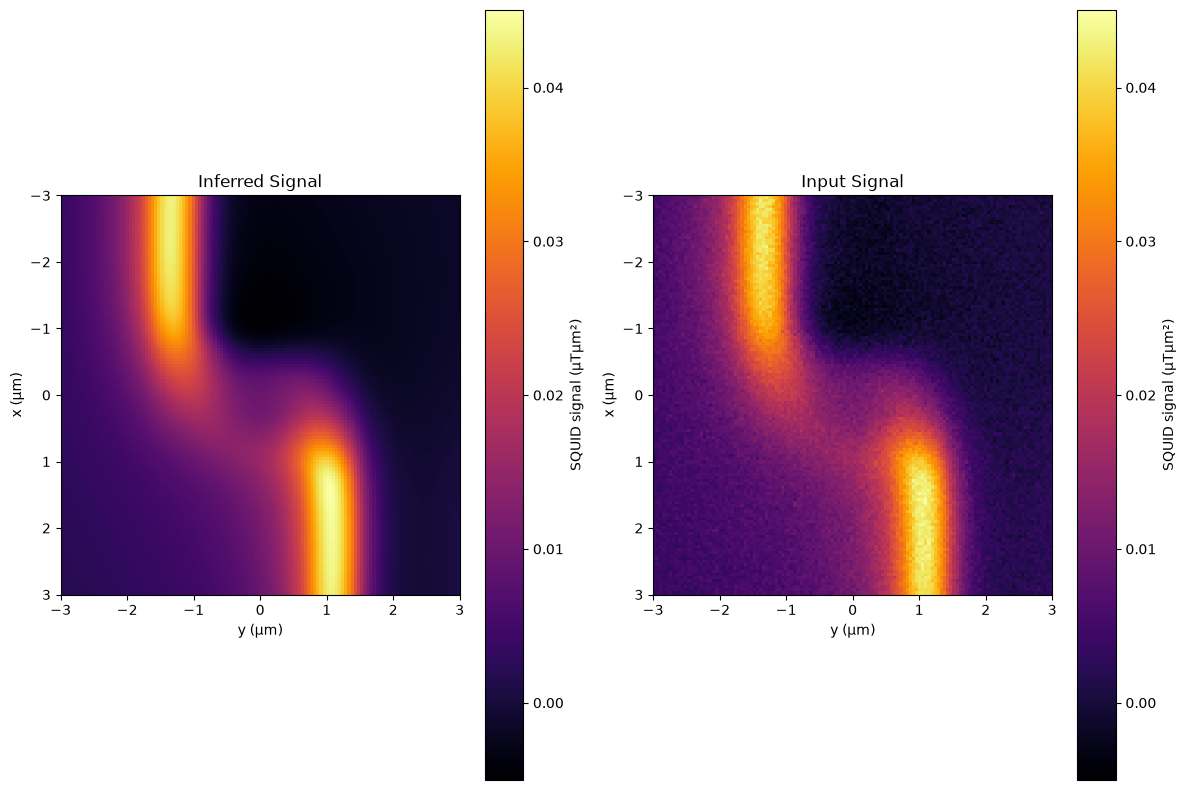

In [9]:
signal_inferred_noisy = fwd.forward(*m2g_perturbed.streamfunction_to_currents(fitres_noisy["streamfunction"]))

fig, (ax_infer, ax_true) = plt.subplots(1,2,figsize=(12,8))
im0 = ax_infer.imshow(signal_inferred_noisy, extent=[-params.Ly / 2, params.Ly / 2, params.Lx / 2, -params.Lx / 2], cmap='inferno')
ax_infer.set_xlabel('y (µm)')
ax_infer.set_ylabel('x (µm)')
ax_infer.set_aspect('equal')
ax_infer.set_title("Inferred Signal")
im1 = ax_true.imshow(signal_noisy, extent=[-params.Ly / 2, params.Ly / 2, params.Lx / 2, -params.Lx / 2], cmap='inferno')
ax_true.set_xlabel('y (µm)')
ax_true.set_ylabel('x (µm)')
ax_true.set_aspect('equal')
ax_true.set_title("Input Signal")
plt.colorbar(im0, ax=ax_infer, label='SQUID signal (µTµm²)')
plt.colorbar(im0, ax=ax_true, label='SQUID signal (µTµm²)')
plt.tight_layout()
plt.show()


To finish, we note that the quality of current reconstruction is still very high. All streamlines follow the ground truth, and the channels are correctly positioned and of realistic width.

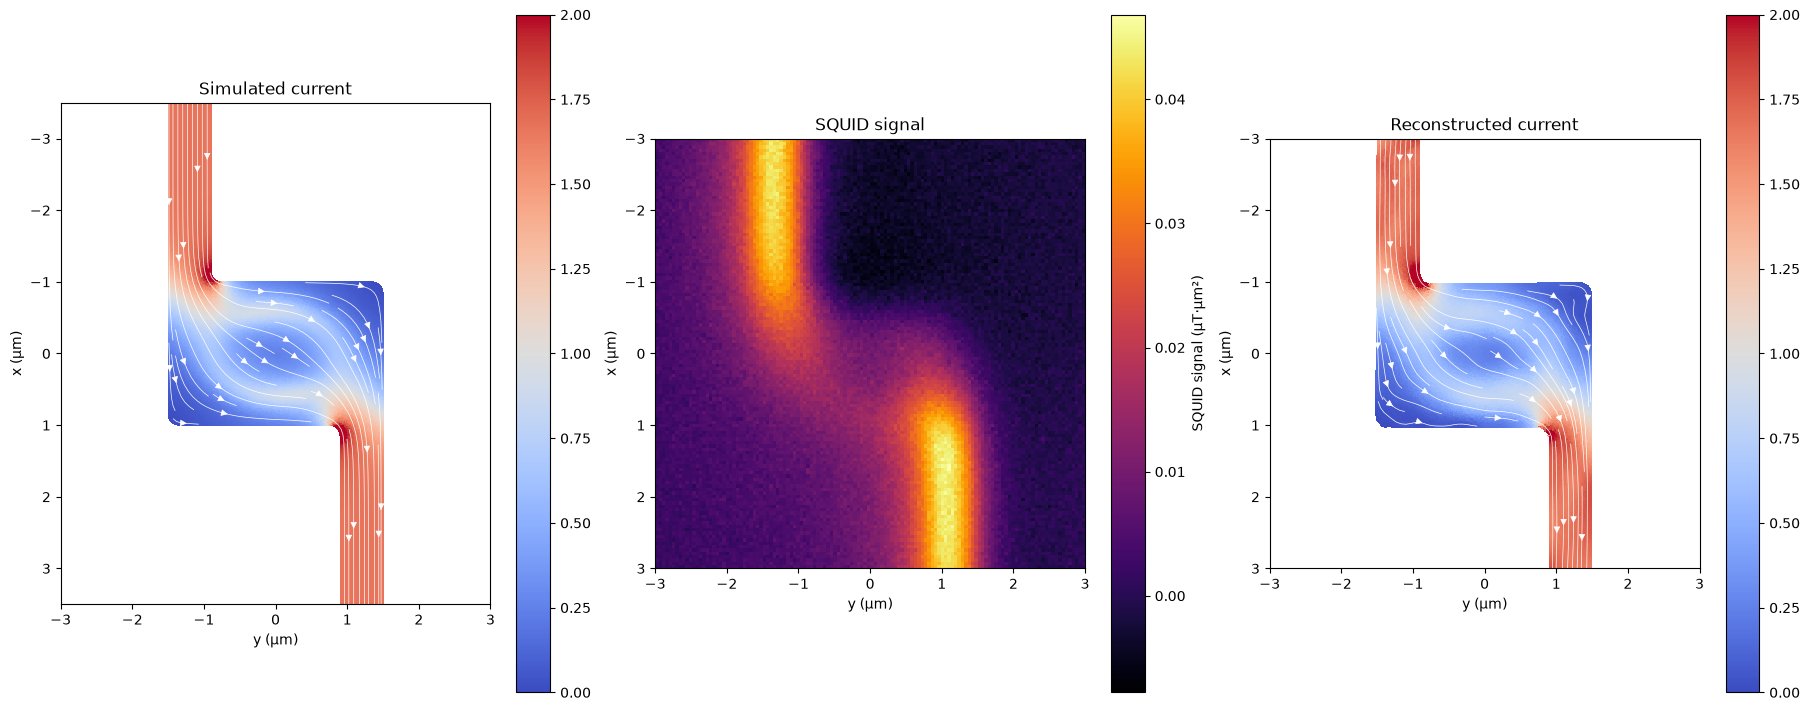

In [10]:
fig, (ax0, ax1, ax2) = plt.subplots(1, 3, figsize=(18, 7), layout="constrained")

# Left: simulated current on the original mesh, 6 um wide by 7 um tall, centred on the device
V = blockmesh.vertices
xc = 0.5 * (V[:, 0].min() + V[:, 0].max())   # vertical centre (x points down)
yc = 0.5 * (V[:, 1].min() + V[:, 1].max())   # horizontal centre
meshplotting.streamplot(blockmesh, ax0, res["Kx"], res["Ky"], n_grid=256, density=1.5,
                        cmap="coolwarm", vmin=0.0, vmax=2)
ax0.set_xlim(yc - 3.0, yc + 3.0)
ax0.set_ylim(xc + 3.5, xc - 3.5)             # 7 um tall, x pointing down
ax0.set_title("Simulated current")

# Middle: the SQUID signal on the 6 x 6 um scan window
im = ax1.imshow(signal_noisy, extent=[-params.Ly / 2, params.Ly / 2, params.Lx / 2, -params.Lx / 2],
                cmap="inferno")
ax1.set_aspect("equal")
plt.colorbar(im, ax=ax1, label="SQUID signal (µT·µm²)")
ax1.set_title("SQUID signal")

# Right: reconstructed current on the perturbed mesh, same 6 x 6 um window as the signal
meshplotting.streamplot(blockmesh_perturbed, ax2, fitres_noisy["Kx"], fitres_noisy["Ky"], n_grid=256,
                        density=1.5, cmap="coolwarm", vmin=0.0, vmax=2)
ax2.set_xlim(-params.Ly / 2, params.Ly / 2)
ax2.set_ylim(params.Lx / 2, -params.Lx / 2)  # x pointing down
ax2.set_title("Reconstructed current")

for ax in (ax0, ax1, ax2):
    ax.set_xlabel("y (µm)")
    ax.set_ylabel("x (µm)")
plt.show()